In [1]:
# 1. Импорт библиотек

using Pkg
## Pkg.add("Plots") 
using Plots # подключаем функции plot(), plot!(), xlabel! и т.д.
using Printf # знаки после запятой

In [2]:
# 2. Ввод исходных данных

print("Введите ёмкость соты C (целое число): ")
C = parse(Int, readline())

print("Введите полнодоступную часть пропускной способности соты g: ")
g = parse(Int, readline())

print("Введите интенсивность обслуживания μ: ")
mu = parse(Float64, readline())

print("Введите интенсивность λ1: ")
lambda1 = parse(Float64, readline())

print("Введите интенсивность λ2: ")
lambda2 = parse(Float64, readline())

## 2.1 Интенсивность предложенной нагрузки: ρ = λ / μ
rho1 = lambda1 / mu
rho2 = lambda2 / mu

println()
println("Введены данные: C=$C, g=$g, μ=$mu, λ1=$lambda1, λ2=$lambda2")

Введите ёмкость соты C (целое число): 

stdin>  90


Введите полнодоступную часть пропускной способности соты g: 

stdin>  60


Введите интенсивность обслуживания μ: 

...

Введите интенсивность λ1: 

stdin>  10


Введите интенсивность λ2: 

stdin>  15



Введены данные: C=90, g=60, μ=0.5, λ1=10.0, λ2=15.0


In [3]:
# 3. Функции расчёта характеристик модели

## 3.1 Стационарное распределение вероятностей состояний системы p(n)
function stationary_probability(rho1::Float64, rho2::Float64, C::Int, g::Int)
    rho_sum = rho1 + rho2

    part_sum = 0.0

    # первая сумма: n = 1,...,g
    for n in 1:g
        part_sum += rho_sum^n / factorial(big(n))
    end

    # вторая сумма: n = g+1,...,C
    for n in g+1:C
        part_sum += rho_sum^g * rho1^(n - g) / factorial(big(n))
    end

    p0 = 1.0 / part_sum # p0 - константа, общая для всех состояний

    # считаем p(n) для каждого состояния
    p = zeros(Float64, C + 1)

    for n in 0:C
        if n <= g
            # полнодоступная часть
            p[n + 1] = p0 * rho_sum^n / factorial(big(n))
        else
            # зарезервированная часть n!
            p[n + 1] = p0 * rho_sum^g * rho1^(n - g) / factorial(big(n))
        end
    end

    return p
end

stationary_probability (generic function with 1 method)

In [4]:
## 3.2 Вероятность блокировки по времени E1
function time_blocking_probability_E1(p::Vector{Float64}, C::Int)
    return p[C + 1]
end

time_blocking_probability_E1 (generic function with 1 method)

In [5]:
## 3.3 Вероятность блокировки по времени E2
function time_blocking_probability_E2(p::Vector{Float64}, C::Int, g::Int)
    return sum(p[g + 1 : C + 1])
end

time_blocking_probability_E2 (generic function with 1 method)

In [6]:
## 3.4 Среднее число N обслуживаемых в системе запросов
function average_requests(p::Vector{Float64}, C::Int)
    N = 0.0
    for n in 0:C
        N += n * p[n + 1]
    end
    return N
end

average_requests (generic function with 1 method)

In [7]:
# 4. Расчёт и вывод стационарного распределения p(n)

p = stationary_probability(rho1, rho2, C, g)

println("=== Стационарное распределение вероятностей p(n) ===")
for n in 0:C
    @printf("p(%d) = %.10f\n", n, p[n + 1])
end

## 4.1 Проверка условия нормировки: сумма всех p(n) должна быть равна 1
total = sum(p)
println()
@printf("Сумма всех вероятностей: %.10f\n", total)

=== Стационарное распределение вероятностей p(n) ===
p(0) = 0.0000000000
p(1) = 0.0000000000
p(2) = 0.0000000000
p(3) = 0.0000000000
p(4) = 0.0000000000
p(5) = 0.0000000000
p(6) = 0.0000000000
p(7) = 0.0000000000
p(8) = 0.0000000000
p(9) = 0.0000000000
p(10) = 0.0000000000
p(11) = 0.0000000000
p(12) = 0.0000000001
p(13) = 0.0000000004
p(14) = 0.0000000014
p(15) = 0.0000000048
p(16) = 0.0000000150
p(17) = 0.0000000441
p(18) = 0.0000001226
p(19) = 0.0000003226
p(20) = 0.0000008064
p(21) = 0.0000019201
p(22) = 0.0000043638
p(23) = 0.0000094864
p(24) = 0.0000197634
p(25) = 0.0000395268
p(26) = 0.0000760131
p(27) = 0.0001407651
p(28) = 0.0002513662
p(29) = 0.0004333900
p(30) = 0.0007223167
p(31) = 0.0011650269
p(32) = 0.0018203545
p(33) = 0.0027581128
p(34) = 0.0040560483
p(35) = 0.0057943547
p(36) = 0.0080477148
p(37) = 0.0108752903
p(38) = 0.0143095925
p(39) = 0.0183456314
p(40) = 0.0229320393
p(41) = 0.0279659016
p(42) = 0.0332927400
p(43) = 0.0387124884
p(44) = 0.0439914640
p(45) = 0.04

In [8]:
# 5. Вероятностные характеристики для введённых данных

## 5.1 Вероятность блокировки по времени E1
E1  = time_blocking_probability_E1(p, C)

@printf("Вероятность блокировки по времени E1 = %.10f\n", E1)

Вероятность блокировки по времени E1 = 0.0000000000


In [9]:
## 5.2 Вероятность блокировки по времени E2
E2  = time_blocking_probability_E2(p, C, g)

@printf("Вероятность блокировки по времени E2 = %.10f\n", E2)

Вероятность блокировки по времени E2 = 0.0317874146


In [10]:
## 5.3 Среднее число обслуживаемых запросов
N  = average_requests(p, C)

@printf("Среднее число обслуживаемых запросов N = %.10f\n", N)

Среднее число обслуживаемых запросов N = 49.0463775608


In [11]:
# 6. Расчёт данных для графиков (задания 3 и 4)

lambda1_range = 0.5:0.5:Float64(C) # последовательность значений λ1 с шагом 0.5

E1_range  = Float64[] # 3 пустых массива (результаты для каждой точки диапазона)
E2_range  = Float64[]
N_range  = Float64[]

for lam1 in lambda1_range # цикл - перебирает каждое значение λ1 из диапазона 
    rho1_i = lam1 / mu # пересчитываем ρ1 конкретно под это значение λ1
    p_i = stationary_probability(rho1_i, rho2, C, g) # заново считаем всё распределение

    E1_i = time_blocking_probability_E1(p_i, C)
    E2_i = time_blocking_probability_E2(p_i, C, g)
    N_i  = average_requests(p_i, C)

    push!(E1_range, E1_i) # и кладём готовые числа в массивы
    push!(E2_range, E2_i)
    push!(N_range, N_i)
end

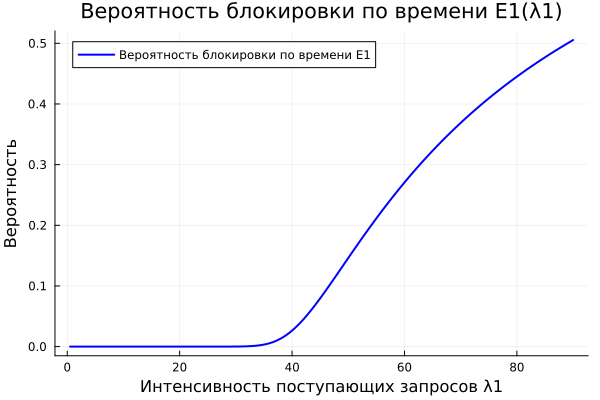

In [12]:
# 7. Построение графиков

## 7.1 График зависимости вероятности блокировки по времени E1 от интенсивности λ1
plot(lambda1_range, E1_range,
     label = "Вероятность блокировки по времени E1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Вероятность",
     title = "Вероятность блокировки по времени E1(λ1)",
     linewidth = 2,
     color = :blue,
     legend = :topleft)

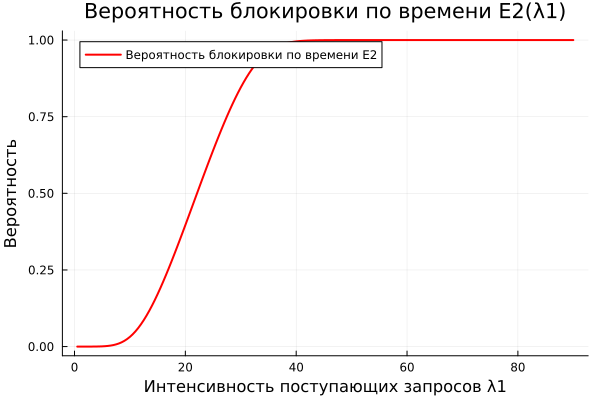

In [13]:
## 7.2 График зависимости вероятности блокировки по времени E2 от интенсивности λ1
plot(lambda1_range, E2_range,
     label = "Вероятность блокировки по времени E2",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Вероятность",
     title = "Вероятность блокировки по времени E2(λ1)",
     linewidth = 2,
     color = :red,
     legend = :topleft)

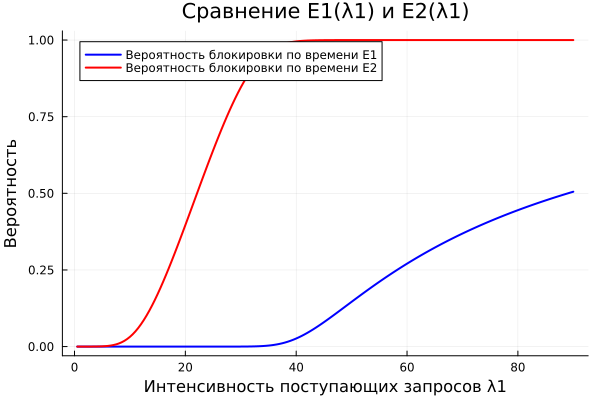

In [14]:
## 7.3 График зависимости вероятности блокировки по времени E1 и E2 от интенсивности λ1
plot(lambda1_range, E1_range,
     label = "Вероятность блокировки по времени E1",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Вероятность",
     title = "Сравнение E1(λ1) и E2(λ1)",
     linewidth = 2,
     color = :blue,
     legend = :topleft)
plot!(lambda1_range, E2_range,
     label = "Вероятность блокировки по времени E2",
     linewidth = 2,
     color = :red)

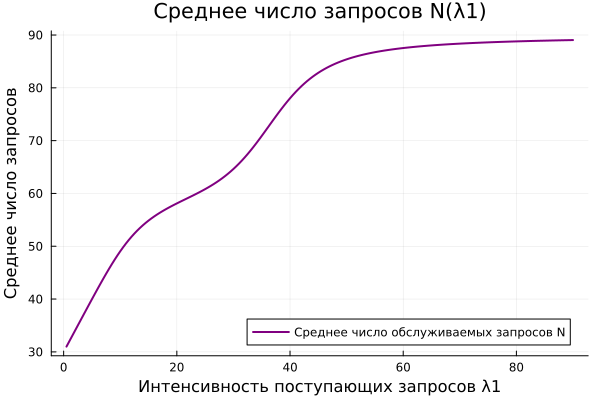

In [15]:
#№ 7.4 График зависимости среднего числа обслуживаемых запросов N от интенсивности λ1
plot(lambda1_range, N_range,
     label = "Среднее число обслуживаемых запросов N",
     xlabel = "Интенсивность поступающих запросов λ1",
     ylabel = "Среднее число запросов",
     title = "Среднее число запросов N(λ1)",
     linewidth = 2,
     color = :purple,
     legend = :bottomright)